# EN3160 Assignment 03: Neural Networks

**Name:** M.R.A. Hakam  
**Index No:** 230224V  
**GitHub:** [github.com/hakammra](https://github.com/hakammra)

### Introduction
this notebook implements the three parts Assignment 03: (1) extending the starter single-layer CIFAR-10 network into a two-layer dense network with $100$ sigmoid hidden units and manual cross-entropy backpropagation, (2) comparing LeNet-5 against a 3-layer Small CNN with batch normalization and dropout on MNIST, and (3) transfer learning with a pretrained ImageNet-1K ResNet-18 on the Hymenoptera (ants vs. bees) dataset via full fine-tuning and frozen feature extraction.

In [1]:
import copy
import os
import random
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

ROOT = Path.cwd()
os.environ['TORCH_HOME'] = str(ROOT / 'data/torch')
torch.set_num_threads(4)

def print_epoch(row, epochs, second='test'):
    print(
        f"Epoch {row['epoch']}/{epochs}  "
        f"train loss {row['train_loss']:.4f}  train accuracy {row['train_accuracy']:.2f}%  "
        f"{second} loss {row[f'{second}_loss']:.4f}  {second} accuracy {row[f'{second}_accuracy']:.2f}%",
        flush=True,
    )


### Question 1: Two-Layer Dense Network on CIFAR-10

starting from Listing 1 in the assignment brief, we extend the linear network into a two-layer network with $D_{\text{in}} = 3072$, a middle hidden layer of $H = 100$ sigmoid units ($h = \sigma(XW_1 + b_1)$), and $K = 10$ output logits ($z = hW_2 + b_2$). Following Lecture Slide 102, we replace Mean Squared Error with cross-entropy loss over softmax probabilities $p_k = \exp(z_k) / \sum_j \exp(z_j)$:
$$L = -\frac{1}{N}\sum_{i=1}^N \log p_{i, y_i}, \qquad \frac{\partial L}{\partial z_{i,k}} = \frac{1}{N}(p_{i,k} - \mathbb{1}[k = y_i])$$
All forward-pass activations, analytical gradients ($\nabla_{W_2}, \nabla_{b_2}, \nabla_{W_1}, \nabla_{b_1}$ via $\sigma'(a) = h(1-h)$), and parameter updates are computed directly with PyTorch tensors (without autograd) for $10$ epochs using batch size $50$, initial learning rate $0.1$, and per-epoch decay $0.9$.

In [2]:
# Two-layer dense network with manual forward pass and analytical cross-entropy gradients
class DenseNetwork:
    def __init__(self, input_size=3072, hidden_size=100, classes=10, seed=0):
        gen = torch.Generator().manual_seed(seed)
        self.w1 = torch.randn(input_size, hidden_size, generator=gen) / (input_size ** 0.5)
        self.b1 = torch.zeros(hidden_size)
        self.w2 = torch.randn(hidden_size, classes, generator=gen) / (hidden_size ** 0.5)
        self.b2 = torch.zeros(classes)

    def forward(self, inputs):
        hidden = torch.sigmoid(inputs @ self.w1 + self.b1)
        logits = hidden @ self.w2 + self.b2
        return hidden, logits

    def gradients(self, inputs, labels):
        hidden, logits = self.forward(inputs)
        log_probs = logits - torch.logsumexp(logits, dim=1, keepdim=True)
        rows = torch.arange(len(labels))
        loss = -log_probs[rows, labels].mean()

        # Softmax + cross-entropy gradient w.r.t. logits: (p - y_onehot) / N
        dlogits = log_probs.exp()
        dlogits[rows, labels] -= 1.0
        dlogits /= len(labels)

        # Backpropagate through output layer and sigmoid hidden layer
        dw2 = hidden.T @ dlogits
        db2 = dlogits.sum(dim=0)
        dhidden = (dlogits @ self.w2.T) * hidden * (1.0 - hidden)
        dw1 = inputs.T @ dhidden
        db1 = dhidden.sum(dim=0)
        return loss, (dw1, db1, dw2, db2)

    def update(self, grads, lr):
        dw1, db1, dw2, db2 = grads
        self.w1 -= lr * dw1
        self.b1 -= lr * db1
        self.w2 -= lr * dw2
        self.b2 -= lr * db2


In [3]:
# CIFAR-10 data loading and evaluation helper
def dense_loaders(batch_size=50, seed=0):
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ])
    trainset = torchvision.datasets.CIFAR10(root=ROOT / 'data', train=True, download=True, transform=transform)
    testset = torchvision.datasets.CIFAR10(root=ROOT / 'data', train=False, download=True, transform=transform)
    gen = torch.Generator().manual_seed(seed)
    trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True, generator=gen, num_workers=0)
    train_eval_loader = DataLoader(trainset, batch_size=batch_size, num_workers=0)
    testloader = DataLoader(testset, batch_size=batch_size, num_workers=0)
    return trainloader, train_eval_loader, testloader

@torch.no_grad()
def evaluate_dense(model, loader):
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        _, logits = model.forward(images.flatten(start_dim=1))
        log_probs = logits - torch.logsumexp(logits, dim=1, keepdim=True)
        total_loss -= log_probs[torch.arange(len(labels)), labels].sum().item()
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += len(labels)
    return total_loss / total, 100.0 * correct / total

def train_dense(epochs=10, batch_size=50, lr=0.1, lr_decay=0.9, seed=0):
    torch.manual_seed(seed)
    trainloader, train_eval_loader, testloader = dense_loaders(batch_size, seed)
    model = DenseNetwork(seed=seed)
    history = []

    for epoch in range(1, epochs + 1):
        for images, labels in trainloader:
            inputs = images.flatten(start_dim=1)
            loss, grads = model.gradients(inputs, labels)
            model.update(grads, lr)

        train_loss, train_acc = evaluate_dense(model, train_eval_loader)
        test_loss, test_acc = evaluate_dense(model, testloader)
        history.append({
            'epoch': epoch,
            'learning_rate': lr,
            'train_loss': train_loss,
            'train_accuracy': train_acc,
            'test_loss': test_loss,
            'test_accuracy': test_acc,
        })
        print_epoch(history[-1], epochs)
        lr *= lr_decay
    return model, history


Epoch 1/10  train loss 1.6917  train accuracy 41.18%  test loss 1.7005  test accuracy 41.25%
Epoch 2/10  train loss 1.6324  train accuracy 43.55%  test loss 1.6610  test accuracy 42.81%
Epoch 3/10  train loss 1.5789  train accuracy 45.87%  test loss 1.6239  test accuracy 44.02%
Epoch 4/10  train loss 1.5431  train accuracy 47.00%  test loss 1.6008  test accuracy 44.61%
Epoch 5/10  train loss 1.4989  train accuracy 48.54%  test loss 1.5739  test accuracy 45.64%
Epoch 6/10  train loss 1.4680  train accuracy 49.60%  test loss 1.5557  test accuracy 46.21%
Epoch 7/10  train loss 1.4447  train accuracy 50.22%  test loss 1.5417  test accuracy 46.65%
Epoch 8/10  train loss 1.4101  train accuracy 51.90%  test loss 1.5226  test accuracy 47.21%
Epoch 9/10  train loss 1.3928  train accuracy 52.43%  test loss 1.5131  test accuracy 47.72%
Epoch 10/10  train loss 1.3724  train accuracy 53.17%  test loss 1.5082  test accuracy 48.31%
Training accuracy: 53.17%
Test accuracy: 48.31%


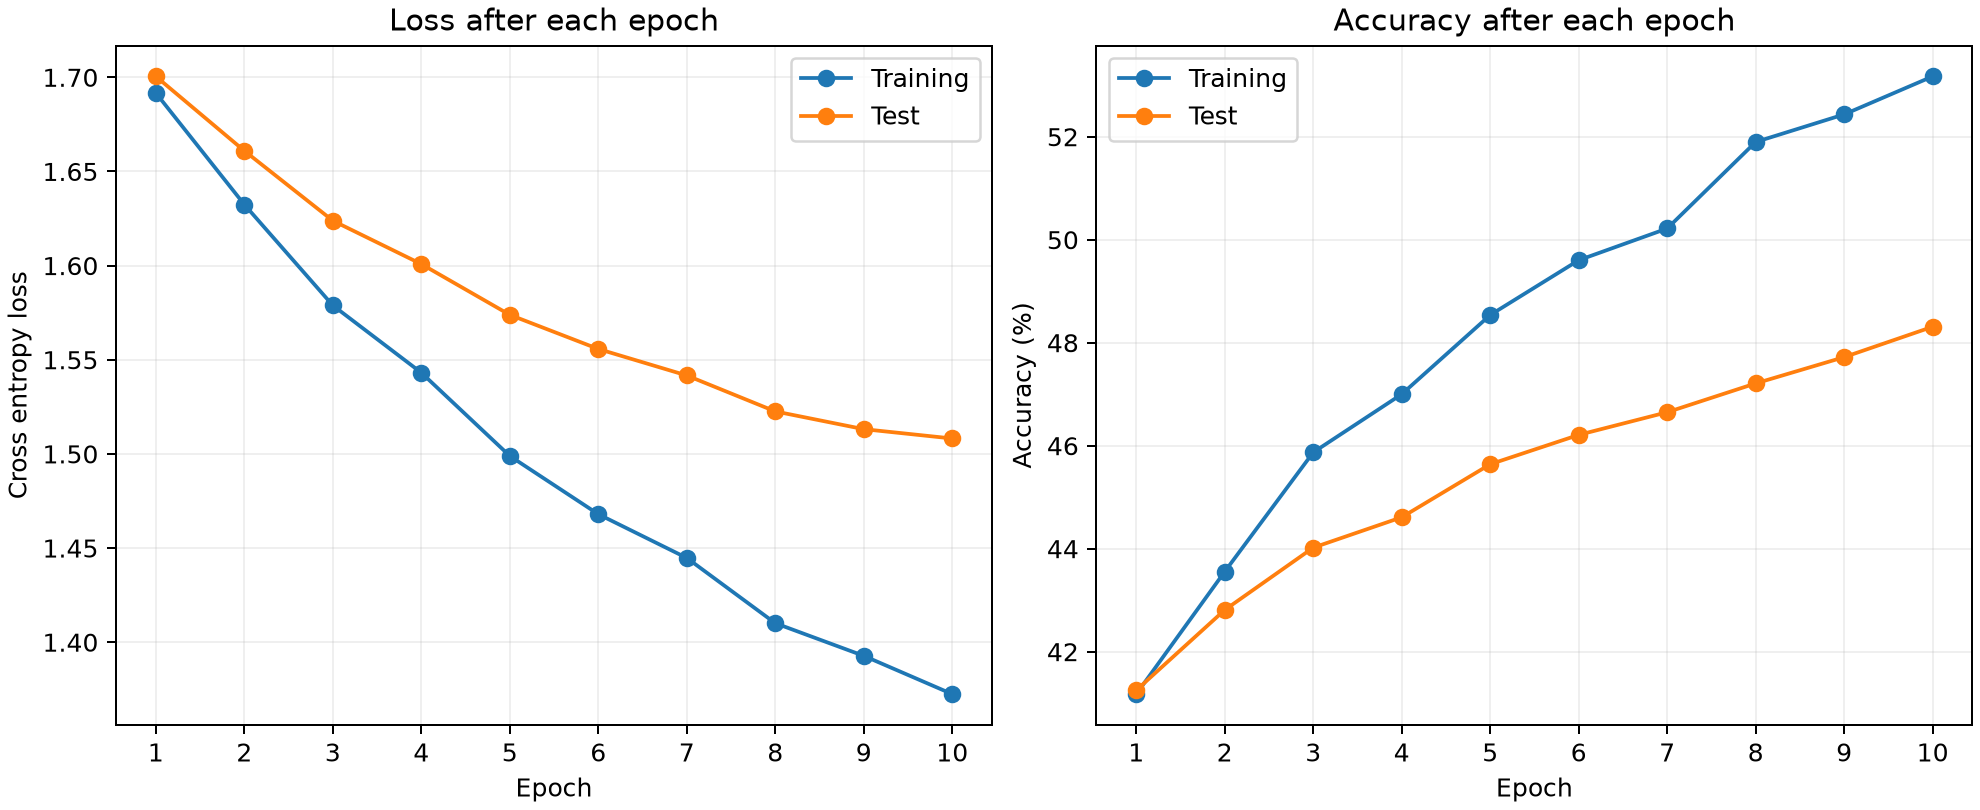

In [4]:
def show_curves(history, title, second='test'):
    epochs = [row['epoch'] for row in history]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
    for phase, label in [('train', 'Training'), (second, 'Validation' if second == 'val' else 'Test')]:
        axes[0].plot(epochs, [row[f'{phase}_loss'] for row in history], label=label)
        axes[1].plot(epochs, [row[f'{phase}_accuracy'] for row in history], label=label)
    axes[0].set(xlabel='Epoch', ylabel='Cross-entropy loss', title=f'{title} loss')
    axes[1].set(xlabel='Epoch', ylabel='Accuracy (%)', title=f'{title} accuracy')
    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend()
    plt.show()

dense_model, dense_history = train_dense()
dense_final = dense_history[-1]
print(f"Training accuracy: {dense_final['train_accuracy']:.2f}%")
print(f"Test accuracy: {dense_final['test_accuracy']:.2f}%")
show_curves(dense_history, 'Dense network')


#### Results and Discussion
After $10$ epochs on CIFAR-10, the two-layer sigmoid network achieves **53.17% training accuracy** and **48.31% test accuracy** (train loss $1.3724$, test loss $1.5082$). Adding the $100$-unit hidden layer with cross-entropy loss and $1/\sqrt{D_{\text{in}}}$ weight scaling substantially improves over the original linear MSE baseline, though the $4.86$ percentage-point generalization gap reflects the spatial invariance limitations of flattening $32 \times 32 \times 3$ RGB images into a fully connected layer.

### Question 2: LeNet-5 and Small CNN on MNIST

Following lenet5_mnist_student.ipynb, MNIST images ($28 \times 28$) are padded by $2$ pixels per side to $32 \times 32$. Both architectures trained under identical conditions: $60,000$ training and $10,000$ test images, $10$ epochs, batch size $50$, Adam optimizer ($\\text{lr} = 0.001$), cross-entropy loss, and seed $0$:
- **Part (a) LeNet-5:** Classical architecture with three $5 \times 5$ Conv2d layers ($1 \to 6 \to 16 \to 120$), Tanh activations, $2 \times 2$ AvgPool2d, and Linear(120, 84) -> Tanh -> Linear(84, 10).
- **Part (b) Modern Small CNN:** Three $3 \times 3$ padded Conv2d blocks ($1 \to 8 \to 16 \to 32$), each followed by BatchNorm2d, ReLU, and $2 \times 2$ MaxPool2d, with a classifier Linear(512, 64) -> ReLU -> Dropout(0.25) -> Linear(64, 10).

In [5]:
# Part (a) LeNet-5 and Part (b) 3-layer Small CNN with BatchNorm and Dropout
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(16, 120, kernel_size=5),
            nn.Tanh(),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.BatchNorm2d(8),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


In [6]:
# Shared MNIST data loaders, evaluation with 10x10 confusion matrix, and training loop
def mnist_loaders(batch_size=50, seed=0):
    transform = transforms.Compose([transforms.Pad(padding=2), transforms.ToTensor()])
    trainset = datasets.MNIST(root=ROOT / 'data', train=True, download=True, transform=transform)
    testset = datasets.MNIST(root=ROOT / 'data', train=False, download=True, transform=transform)
    gen = torch.Generator().manual_seed(seed)
    trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True, generator=gen, num_workers=0)
    train_eval_loader = DataLoader(trainset, batch_size=batch_size, num_workers=0)
    testloader = DataLoader(testset, batch_size=batch_size, num_workers=0)
    return trainloader, train_eval_loader, testloader

@torch.no_grad()
def evaluate_mnist(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    confusion = torch.zeros((10, 10), dtype=torch.int64)
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * len(labels)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += len(labels)
        pairs = labels.cpu() * 10 + preds.cpu()
        confusion += torch.bincount(pairs, minlength=100).reshape(10, 10)
    return total_loss / total, 100.0 * correct / total, confusion

def train_mnist(model_class, epochs=10, batch_size=50, lr=0.001, seed=0):
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)
    device = torch.device('cpu')
    trainloader, train_eval_loader, testloader = mnist_loaders(batch_size, seed)
    model = model_class().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()

        train_loss, train_acc, _ = evaluate_mnist(model, train_eval_loader, criterion, device)
        test_loss, test_acc, confusion = evaluate_mnist(model, testloader, criterion, device)
        history.append({
            'epoch': epoch,
            'train_loss': train_loss,
            'train_accuracy': train_acc,
            'test_loss': test_loss,
            'test_accuracy': test_acc,
        })
        print_epoch(history[-1], epochs)
    return model, history, confusion


#### Question 2(a): LeNet-5 Training and Evaluation

Epoch 1/10  train loss 0.1099  train accuracy 96.67%  test loss 0.1091  test accuracy 96.54%
Epoch 2/10  train loss 0.0604  train accuracy 98.25%  test loss 0.0714  test accuracy 97.90%
Epoch 3/10  train loss 0.0496  train accuracy 98.45%  test loss 0.0627  test accuracy 98.03%
Epoch 4/10  train loss 0.0323  train accuracy 99.05%  test loss 0.0561  test accuracy 98.20%
Epoch 5/10  train loss 0.0268  train accuracy 99.18%  test loss 0.0517  test accuracy 98.44%
Epoch 6/10  train loss 0.0253  train accuracy 99.19%  test loss 0.0536  test accuracy 98.26%
Epoch 7/10  train loss 0.0172  train accuracy 99.49%  test loss 0.0438  test accuracy 98.66%
Epoch 8/10  train loss 0.0150  train accuracy 99.55%  test loss 0.0446  test accuracy 98.63%
Epoch 9/10  train loss 0.0147  train accuracy 99.55%  test loss 0.0516  test accuracy 98.52%
Epoch 10/10  train loss 0.0174  train accuracy 99.44%  test loss 0.0572  test accuracy 98.40%
Training accuracy: 99.44%
Test accuracy: 98.40%


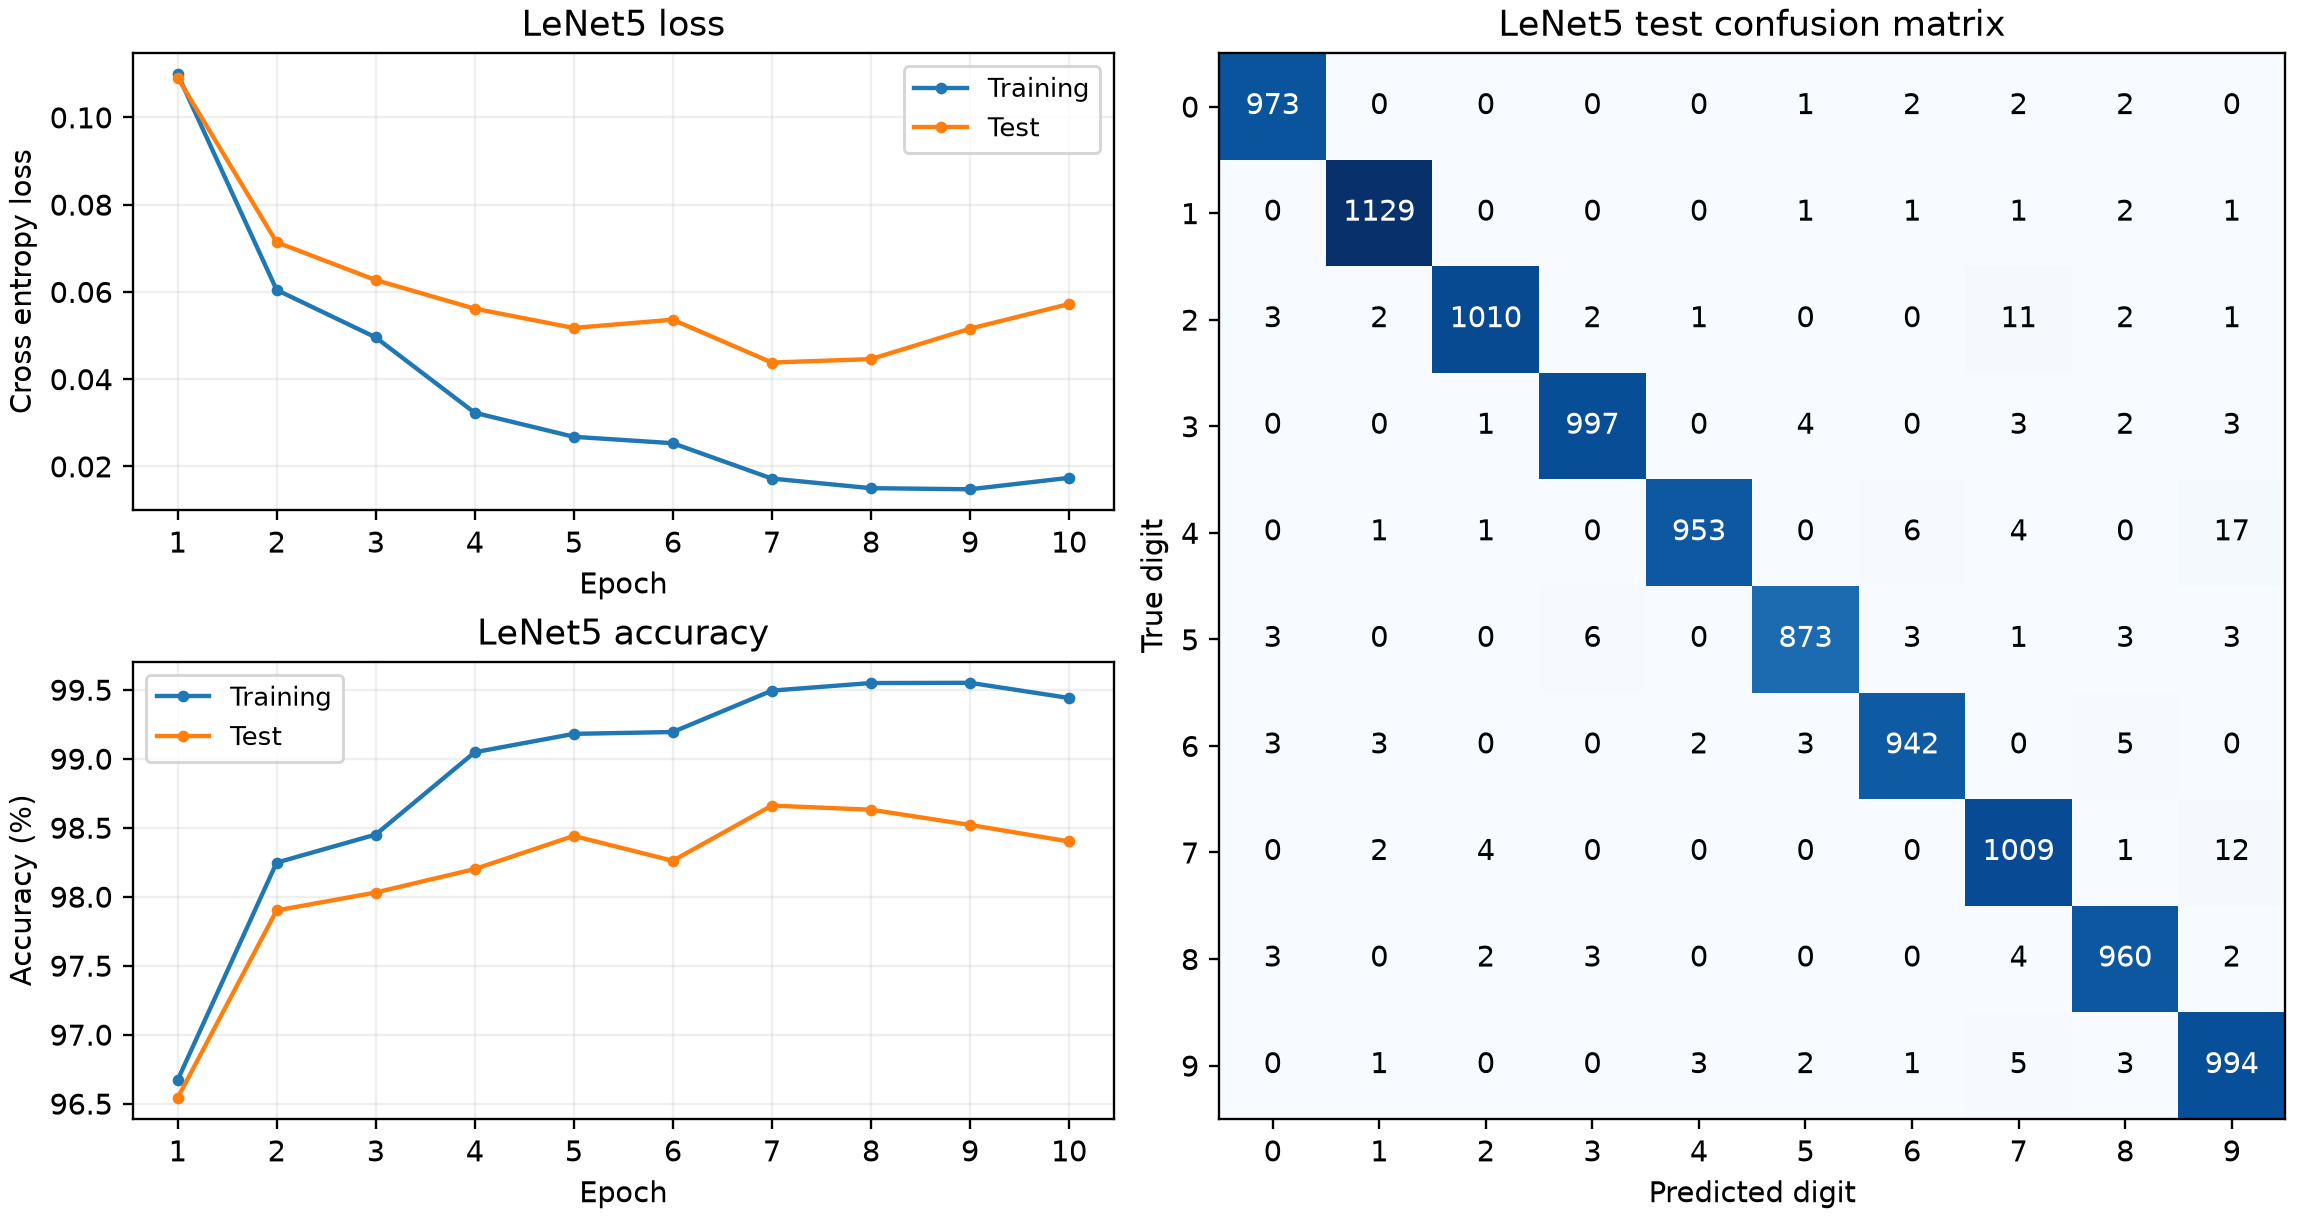

In [7]:
def show_mnist(history, confusion, title):
    epochs = [row['epoch'] for row in history]
    fig = plt.figure(figsize=(11, 5.8), layout='constrained')
    grid = fig.add_gridspec(2, 2, width_ratios=[1, 1.12])
    ax_loss = fig.add_subplot(grid[0, 0])
    ax_acc = fig.add_subplot(grid[1, 0])
    ax_cm = fig.add_subplot(grid[:, 1])

    for phase, label in [('train', 'Training'), ('test', 'Test')]:
        ax_loss.plot(epochs, [row[f'{phase}_loss'] for row in history], marker='o', markersize=3, label=label)
        ax_acc.plot(epochs, [row[f'{phase}_accuracy'] for row in history], marker='o', markersize=3, label=label)

    ax_loss.set(xlabel='Epoch', ylabel='Cross-entropy loss', title=f'{title} loss')
    ax_acc.set(xlabel='Epoch', ylabel='Accuracy (%)', title=f'{title} accuracy')
    for ax in (ax_loss, ax_acc):
        ax.set_xticks(epochs)
        ax.grid(alpha=0.2)
        ax.legend()

    ax_cm.imshow(confusion.numpy(), cmap='Blues')
    ax_cm.set(xticks=range(10), yticks=range(10), xlabel='Predicted digit', ylabel='True digit',
              title=f'{title} test confusion matrix')
    thresh = confusion.max().item() / 2
    for r in range(10):
        for c in range(10):
            val = confusion[r, c].item()
            ax_cm.text(c, r, str(val), ha='center', va='center', fontsize=10,
                       color='white' if val > thresh else 'black')
    plt.show()

lenet_model, lenet_history, lenet_confusion = train_mnist(LeNet5)
lenet_final = lenet_history[-1]
print(f"Training accuracy: {lenet_final['train_accuracy']:.2f}%")
print(f"Test accuracy: {lenet_final['test_accuracy']:.2f}%")
show_mnist(lenet_history, lenet_confusion, 'LeNet-5')


After $10$ epochs, LeNet-5 reaches **99.44% training accuracy** and **98.40% test accuracy** ($9,840 / 10,000$ test digits correct). Notice that while training loss drops monotonically to $0.0174$, test loss reaches its minimum at epoch 7 ($0.0438$, test accuracy $98.66\%$) and creeps up to $0.0572$ by epoch 10—indicating mild overfitting in the unregularized dense layers. The most frequent confusion is $17$ instances of digit 4 misclassified as 9, followed by $12$ instances of 7 predicted as 9.

#### Question 2(b): Small CNN with Batch Normalization and Dropout

Epoch 1/10  train loss 0.0579  train accuracy 98.19%  test loss 0.0530  test accuracy 98.20%
Epoch 2/10  train loss 0.0391  train accuracy 98.83%  test loss 0.0470  test accuracy 98.44%
Epoch 3/10  train loss 0.0329  train accuracy 98.96%  test loss 0.0382  test accuracy 98.75%
Epoch 4/10  train loss 0.0395  train accuracy 98.77%  test loss 0.0506  test accuracy 98.34%
Epoch 5/10  train loss 0.0323  train accuracy 98.94%  test loss 0.0451  test accuracy 98.55%
Epoch 6/10  train loss 0.0257  train accuracy 99.16%  test loss 0.0423  test accuracy 98.57%
Epoch 7/10  train loss 0.0215  train accuracy 99.29%  test loss 0.0411  test accuracy 98.68%
Epoch 8/10  train loss 0.0189  train accuracy 99.40%  test loss 0.0351  test accuracy 98.94%
Epoch 9/10  train loss 0.0128  train accuracy 99.62%  test loss 0.0348  test accuracy 98.88%
Epoch 10/10  train loss 0.0147  train accuracy 99.50%  test loss 0.0378  test accuracy 98.82%
Training accuracy: 99.50%
Test accuracy: 98.82%


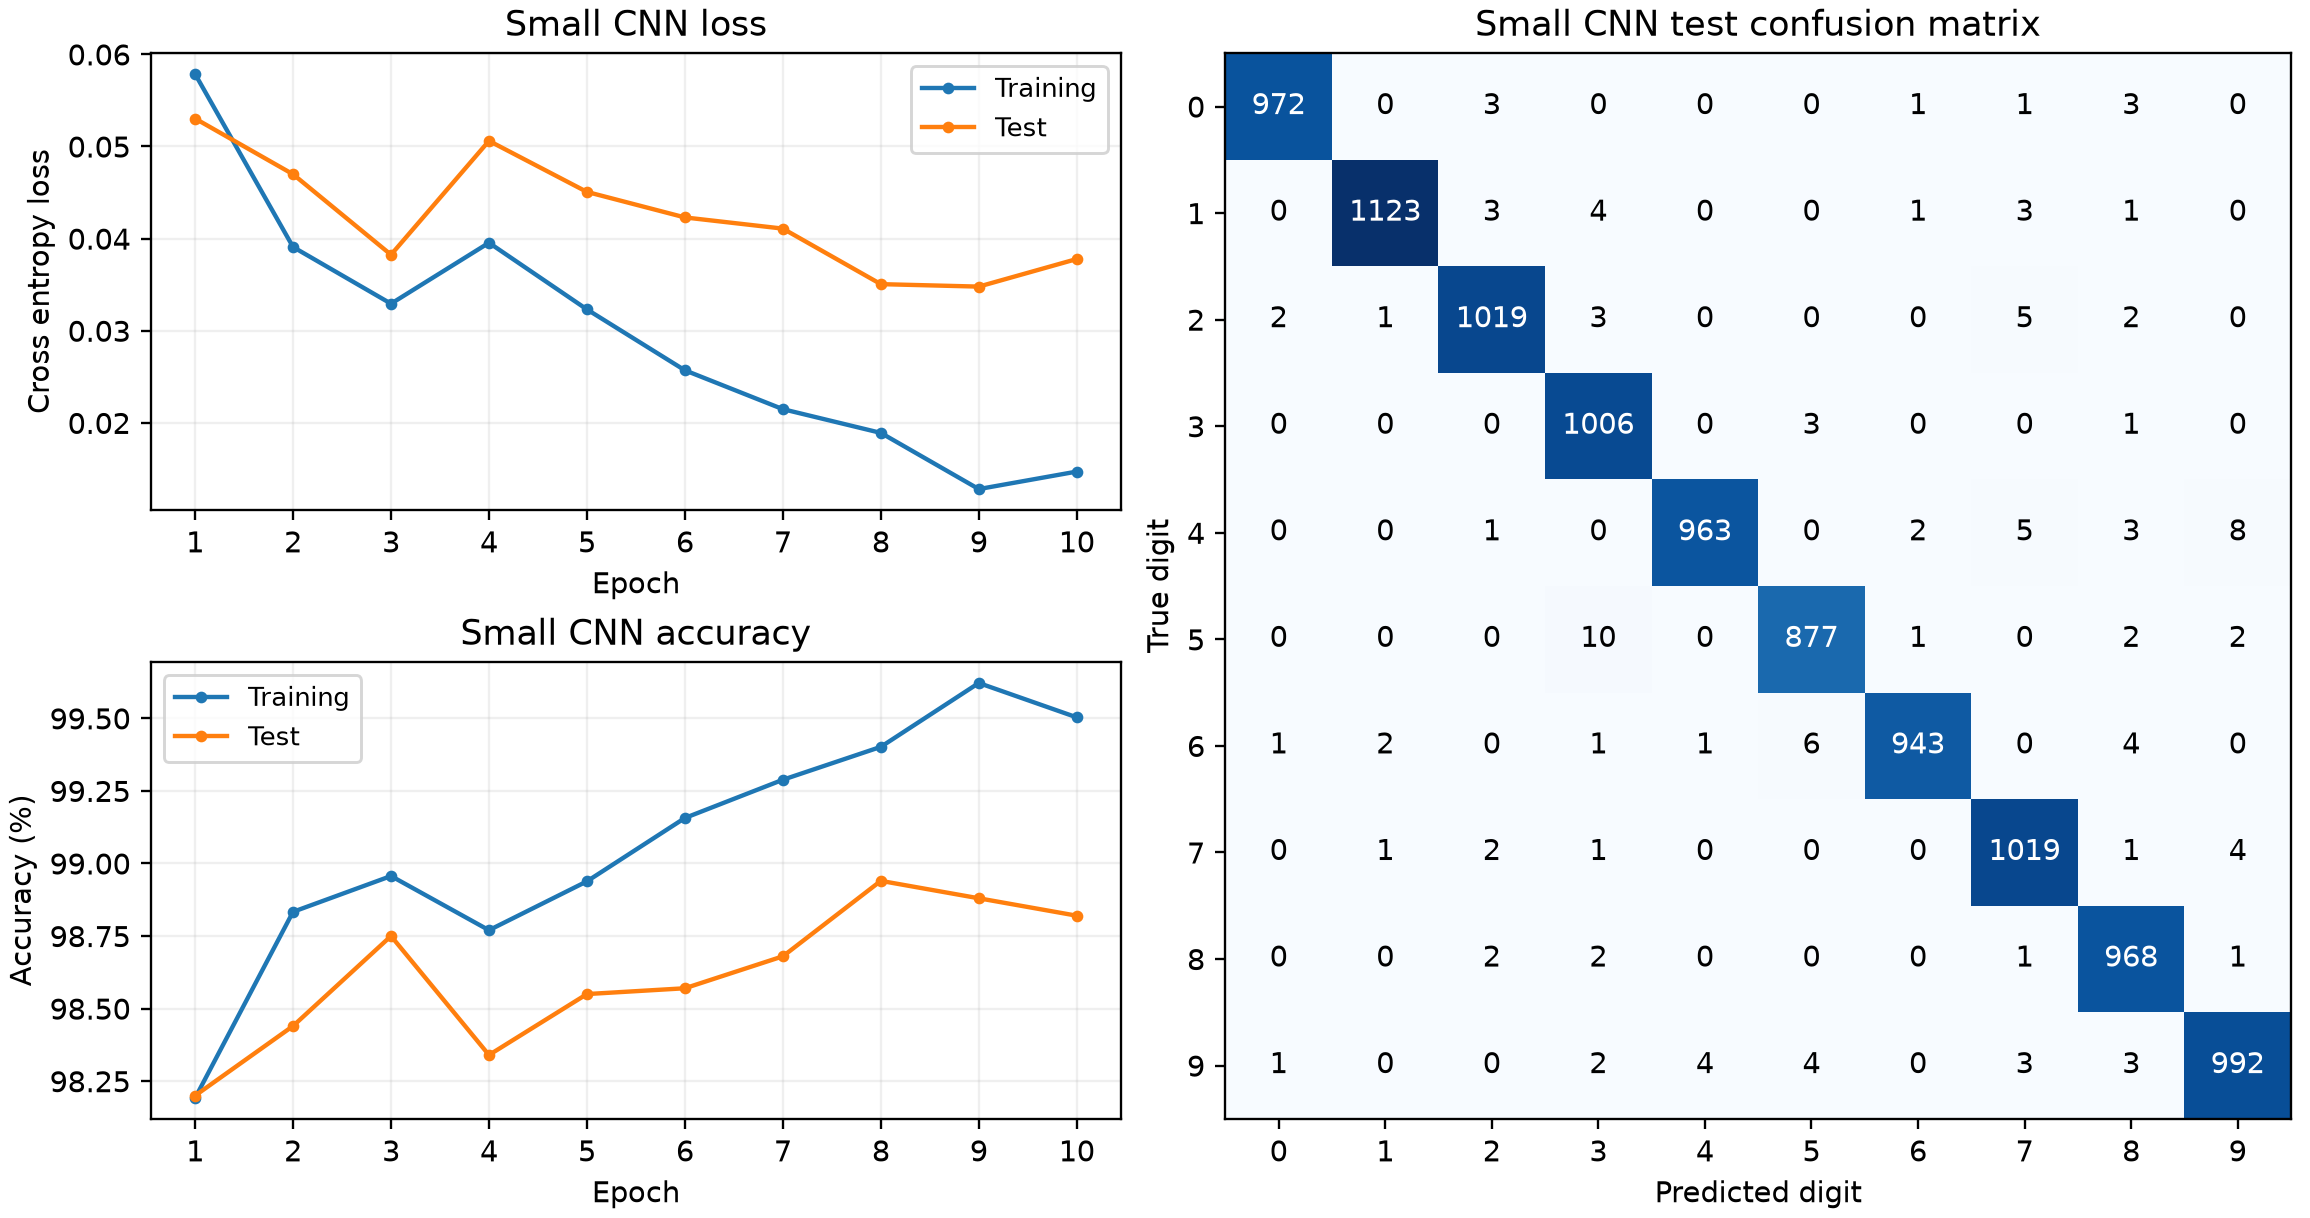

In [8]:
cnn_model, cnn_history, cnn_confusion = train_mnist(SmallCNN)
cnn_final = cnn_history[-1]
print(f"Training accuracy: {cnn_final['train_accuracy']:.2f}%")
print(f"Test accuracy: {cnn_final['test_accuracy']:.2f}%")
show_mnist(cnn_history, cnn_confusion, 'Small CNN')


#### Results and Discussion
The 3-layer Small CNN achieves **99.50% training accuracy** and **98.82% test accuracy** ($9,882 / 10,000$ correct)—outperforming LeNet-5 by **0.42 percentage points** ($42$ fewer test errors) while keeping test loss substantially lower ($0.0378$ vs. $0.0572$). Batch normalization accelerates early convergence ($98.20\%$ test accuracy in epoch 1 vs. $96.54\%$ for LeNet-5), while ReLU, MaxPool2d, and Dropout(0.25) curb late-epoch overfitting. Its largest off-diagonal confusion is only $10$ images of digit 5 predicted as 3.

### Question 3: Transfer Learning with ResNet-18 on Hymenoptera

Following the official PyTorch Transfer Learning tutorial, we load resnet18(weights=ResNet18_Weights.IMAGENET1K_V1) and replace model.fc with nn.Linear(512, 2) to classify ants vs. bees ($244$ training images, $153$ validation images). Training uses RandomResizedCrop(224) and RandomHorizontalFlip(), whereas validation uses deterministic Resize(256) and CenterCrop(224) with ImageNet normalization. Both methods run for $25$ epochs with batch size $4$, SGD(lr=0.001, momentum=0.9), StepLR(step_size=7, gamma=0.1), and checkpoint selection by best validation accuracy.

In [9]:
# Hymenoptera data loaders and transfer learning training loop
def transfer_loaders(batch_size=4, seed=0):
    data_dir = ROOT / 'data/hymenoptera_data'
    if not (data_dir / 'train').exists():
        data_dir.parent.mkdir(parents=True, exist_ok=True)
        archive = data_dir.parent / 'hymenoptera_data.zip'
        if not archive.exists():
            urllib.request.urlretrieve('https://download.pytorch.org/tutorial/hymenoptera_data.zip', archive)
        with zipfile.ZipFile(archive) as zf:
            zf.extractall(data_dir.parent)

    mean = [0.485, 0.456, 0.406]
    std = [0.229, 0.224, 0.225]
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    val_tf = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    trainset = datasets.ImageFolder(data_dir / 'train', train_tf)
    valset = datasets.ImageFolder(data_dir / 'val', val_tf)
    gen = torch.Generator().manual_seed(seed)
    return {
        'train': DataLoader(trainset, batch_size=batch_size, shuffle=True, generator=gen, num_workers=0),
        'val': DataLoader(valset, batch_size=batch_size, shuffle=False, num_workers=0),
    }

@torch.no_grad()
def evaluate_transfer(model, loader, criterion, device):
    model.eval()
    loss_sum = 0.0
    correct = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss_sum += criterion(logits, labels).item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
    total = len(loader.dataset)
    return {'loss': loss_sum / total, 'accuracy': 100.0 * correct / total, 'correct': correct, 'total': total}

def train_resnet(frozen=False, epochs=25, seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    loaders = transfer_loaders(seed=seed)
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1, progress=False)
    if frozen:
        for param in model.parameters():
            param.requires_grad = False

    model.fc = nn.Linear(model.fc.in_features, len(loaders['train'].dataset.classes))
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    params = model.fc.parameters() if frozen else model.parameters()
    optimizer = torch.optim.SGD(params, lr=0.001, momentum=0.9)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

    best_correct = -1
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())
    history = []

    for epoch in range(1, epochs + 1):
        if frozen:
            model.eval()
            model.fc.train()
        else:
            model.train()

        train_loss = 0.0
        train_correct = 0
        lr = optimizer.param_groups[0]['lr']
        for images, labels in loaders['train']:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(labels)
            train_correct += (logits.argmax(dim=1) == labels).sum().item()

        scheduler.step()
        val_metrics = evaluate_transfer(model, loaders['val'], criterion, device)
        n_train = len(loaders['train'].dataset)
        row = {
            'epoch': epoch,
            'learning_rate': lr,
            'train_loss': train_loss / n_train,
            'train_accuracy': 100.0 * train_correct / n_train,
            'val_loss': val_metrics['loss'],
            'val_accuracy': val_metrics['accuracy'],
        }
        history.append(row)
        print_epoch(row, epochs, second='val')

        if val_metrics['correct'] > best_correct:
            best_correct = val_metrics['correct']
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    selected = evaluate_transfer(model, loaders['val'], criterion, device)
    return model, history, best_epoch, selected


#### Question 3(a): Fine-Tuning All ResNet-18 Layers

Epoch 1/25  train loss 0.5356  train accuracy 72.54%  val loss 0.4272  val accuracy 84.31%
Epoch 2/25  train loss 0.5643  train accuracy 77.46%  val loss 0.3393  val accuracy 86.93%
Epoch 3/25  train loss 0.5791  train accuracy 81.15%  val loss 0.3081  val accuracy 88.24%
Epoch 4/25  train loss 0.5510  train accuracy 76.64%  val loss 0.2903  val accuracy 86.27%
Epoch 5/25  train loss 0.5176  train accuracy 79.51%  val loss 0.3291  val accuracy 90.85%
Epoch 6/25  train loss 0.4344  train accuracy 84.43%  val loss 0.2862  val accuracy 90.20%
Epoch 7/25  train loss 0.4762  train accuracy 82.38%  val loss 0.4524  val accuracy 83.01%
Epoch 8/25  train loss 0.4002  train accuracy 82.38%  val loss 0.2977  val accuracy 89.54%
Epoch 9/25  train loss 0.3812  train accuracy 85.25%  val loss 0.2790  val accuracy 89.54%
Epoch 10/25  train loss 0.3105  train accuracy 86.89%  val loss 0.2406  val accuracy 91.50%
Epoch 11/25  train loss 0.3591  train accuracy 82.79%  val loss 0.2382  val accuracy 92.1

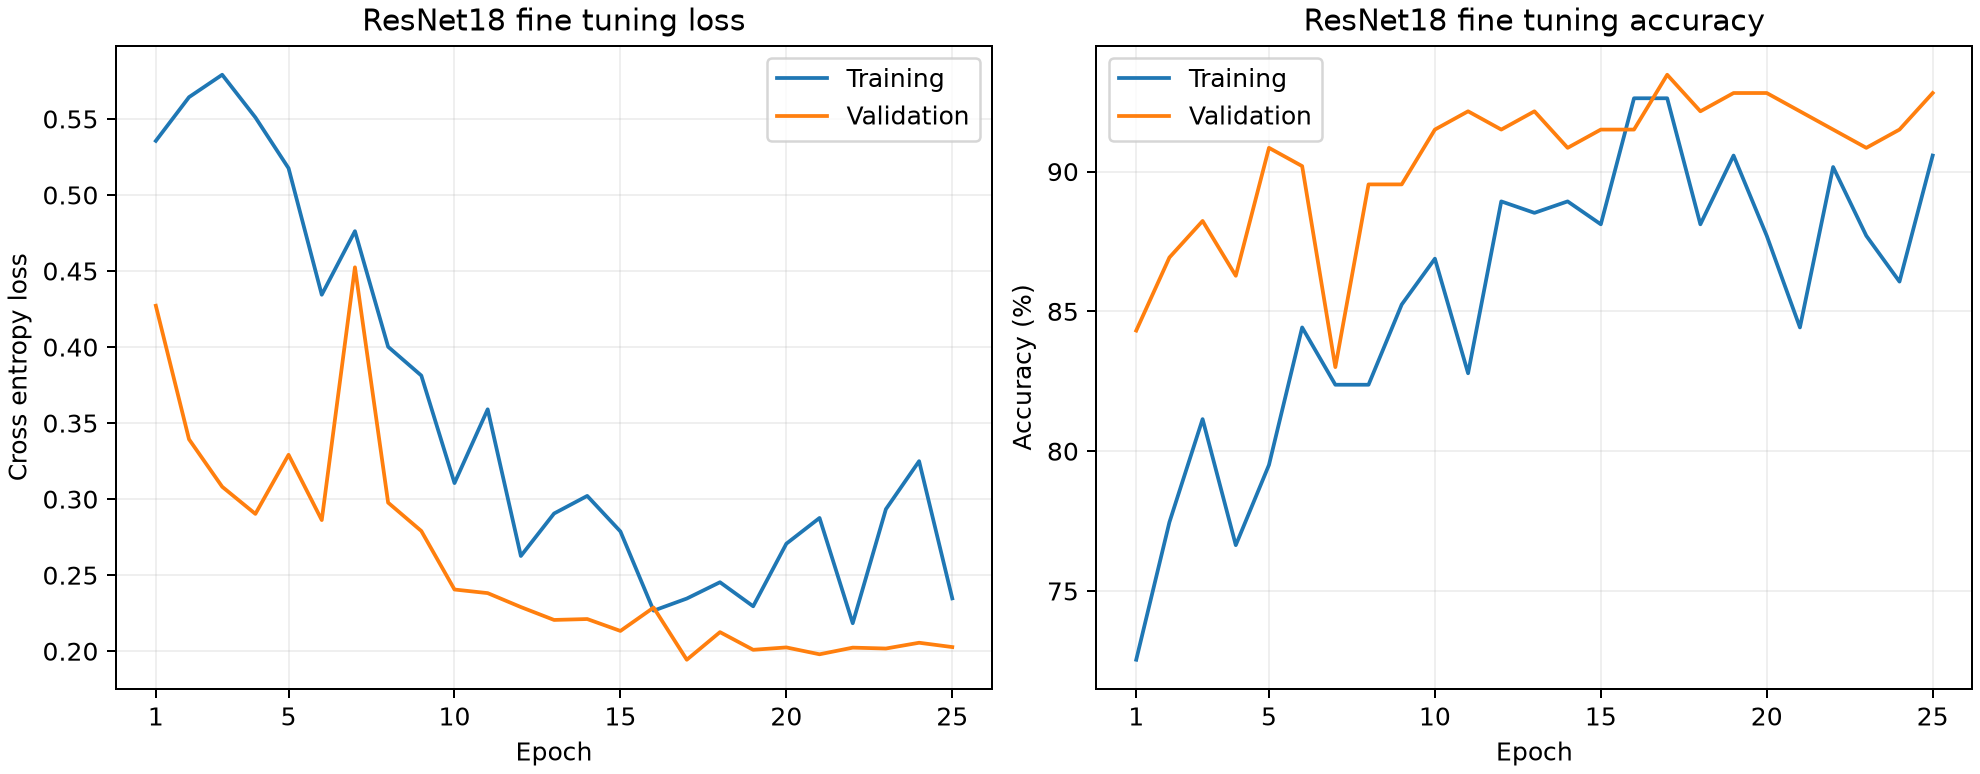

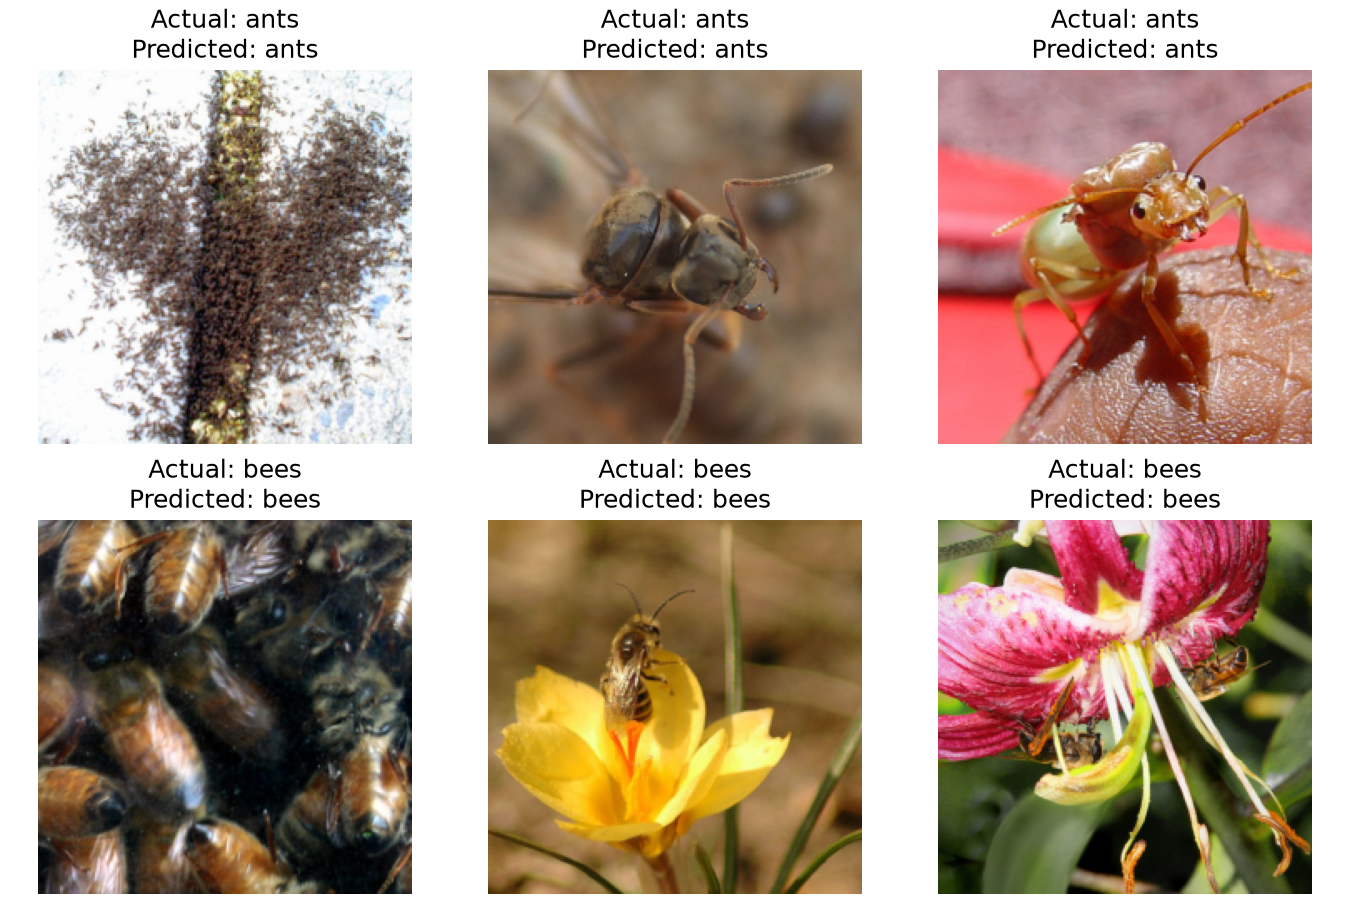

In [10]:
@torch.no_grad()
def show_predictions(model, loader, device):
    model.eval()
    dataset = loader.dataset
    indices = [0, 1, 2] + [idx for idx, target in enumerate(dataset.targets) if target == 1][:3]
    images, targets = zip(*(dataset[idx] for idx in indices))
    batch = torch.stack(images)
    preds = model(batch.to(device)).argmax(dim=1).cpu().tolist()

    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    fig, axes = plt.subplots(2, 3, figsize=(9, 6), layout='constrained')
    for ax, img, target, pred in zip(axes.flat, images, targets, preds):
        ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy())
        ax.set_title(f"Actual: {dataset.classes[target]}\nPredicted: {dataset.classes[pred]}")
        ax.axis('off')
    plt.show()

fine_model, fine_history, fine_epoch, fine_val = train_resnet(frozen=False)
print(f"Best validation accuracy: {fine_val['accuracy']:.2f}%")
print(f"Selected epoch: {fine_epoch} of {len(fine_history)}")
show_curves(fine_history, 'ResNet-18 fine-tuning', second='val')
show_predictions(fine_model, transfer_loaders()['val'], next(fine_model.parameters()).device)


when fine-tuning all $11,177,538$ parameters, ResNet-18 reaches its highest validation accuracy of **93.46%** ($143 / 153$ correct, validation loss $0.1944$) at **epoch 17**, finishing at $92.81\%$ ($142 / 153$) at epoch 25. Notice that in the early epochs, validation accuracy exceeds training accuracy because training batches undergo aggressive RandomResizedCrop(224) and horizontal flips while validation images use clean center crops in evaluation mode.

#### Question 3(b): ResNet-18 as a Frozen Feature Extractor

Epoch 1/25  train loss 0.3824  train accuracy 81.56%  val loss 0.1603  val accuracy 95.42%
Epoch 2/25  train loss 0.1558  train accuracy 93.85%  val loss 0.1337  val accuracy 95.42%
Epoch 3/25  train loss 0.1569  train accuracy 93.85%  val loss 0.1674  val accuracy 94.77%
Epoch 4/25  train loss 0.1887  train accuracy 91.39%  val loss 0.1888  val accuracy 94.12%
Epoch 5/25  train loss 0.1023  train accuracy 94.67%  val loss 0.1653  val accuracy 94.77%
Epoch 6/25  train loss 0.0996  train accuracy 96.31%  val loss 0.1610  val accuracy 94.77%
Epoch 7/25  train loss 0.1093  train accuracy 95.49%  val loss 0.1507  val accuracy 95.42%
Epoch 8/25  train loss 0.0794  train accuracy 98.36%  val loss 0.1475  val accuracy 95.42%
Epoch 9/25  train loss 0.0966  train accuracy 97.13%  val loss 0.1552  val accuracy 94.77%
Epoch 10/25  train loss 0.0569  train accuracy 97.95%  val loss 0.1497  val accuracy 95.42%
Epoch 11/25  train loss 0.0676  train accuracy 97.95%  val loss 0.1507  val accuracy 95.4

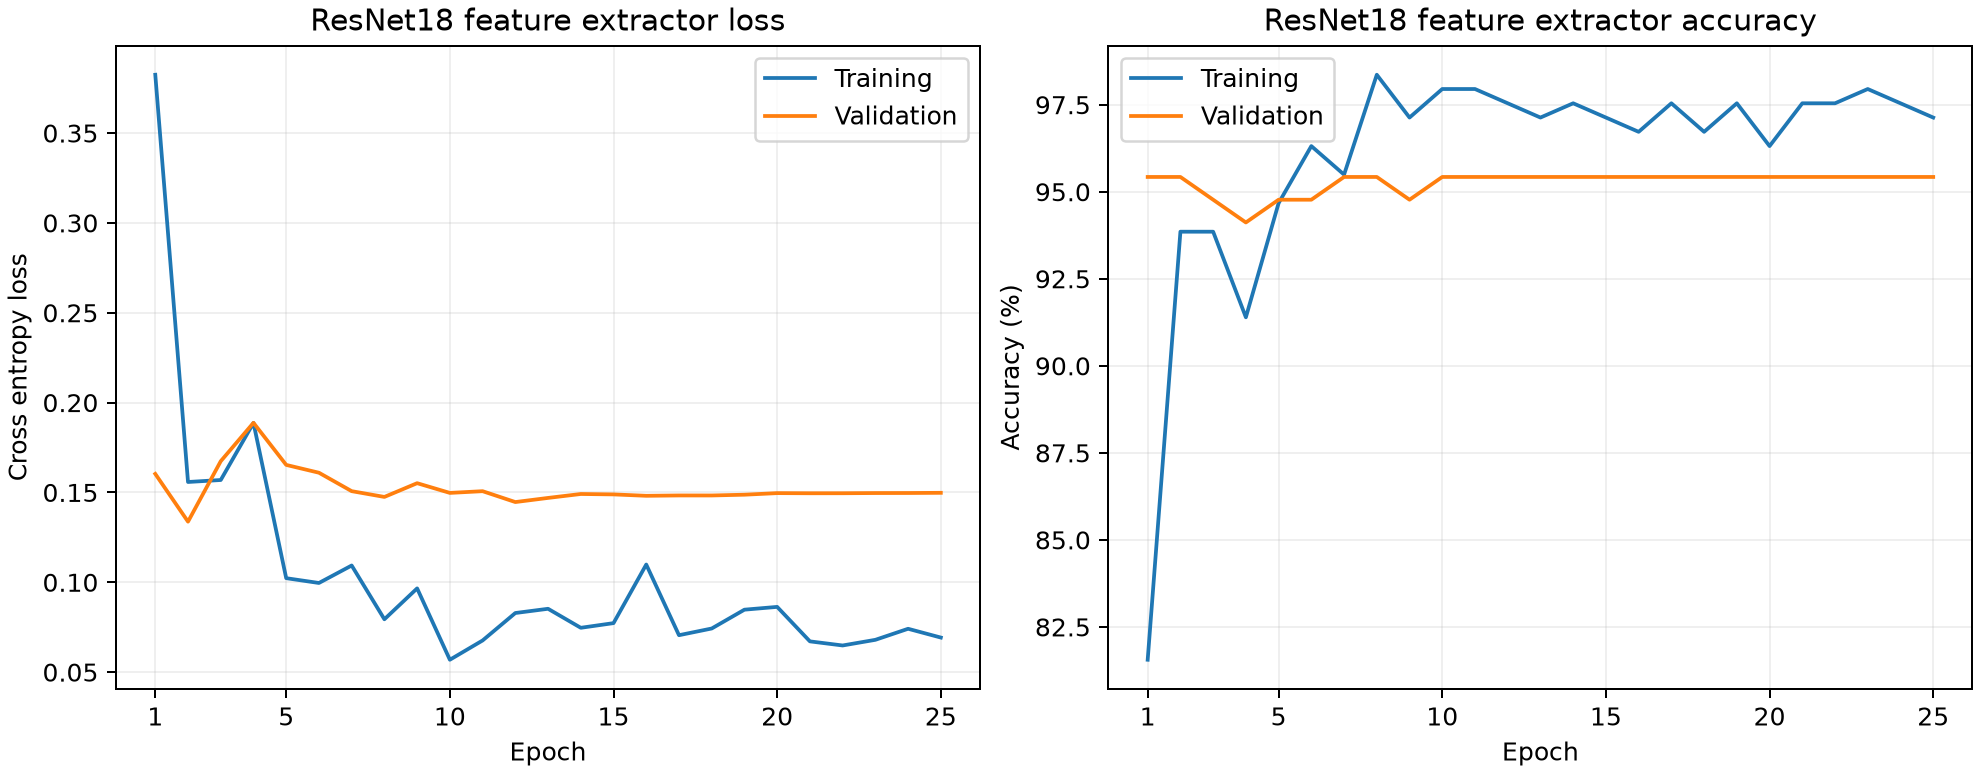

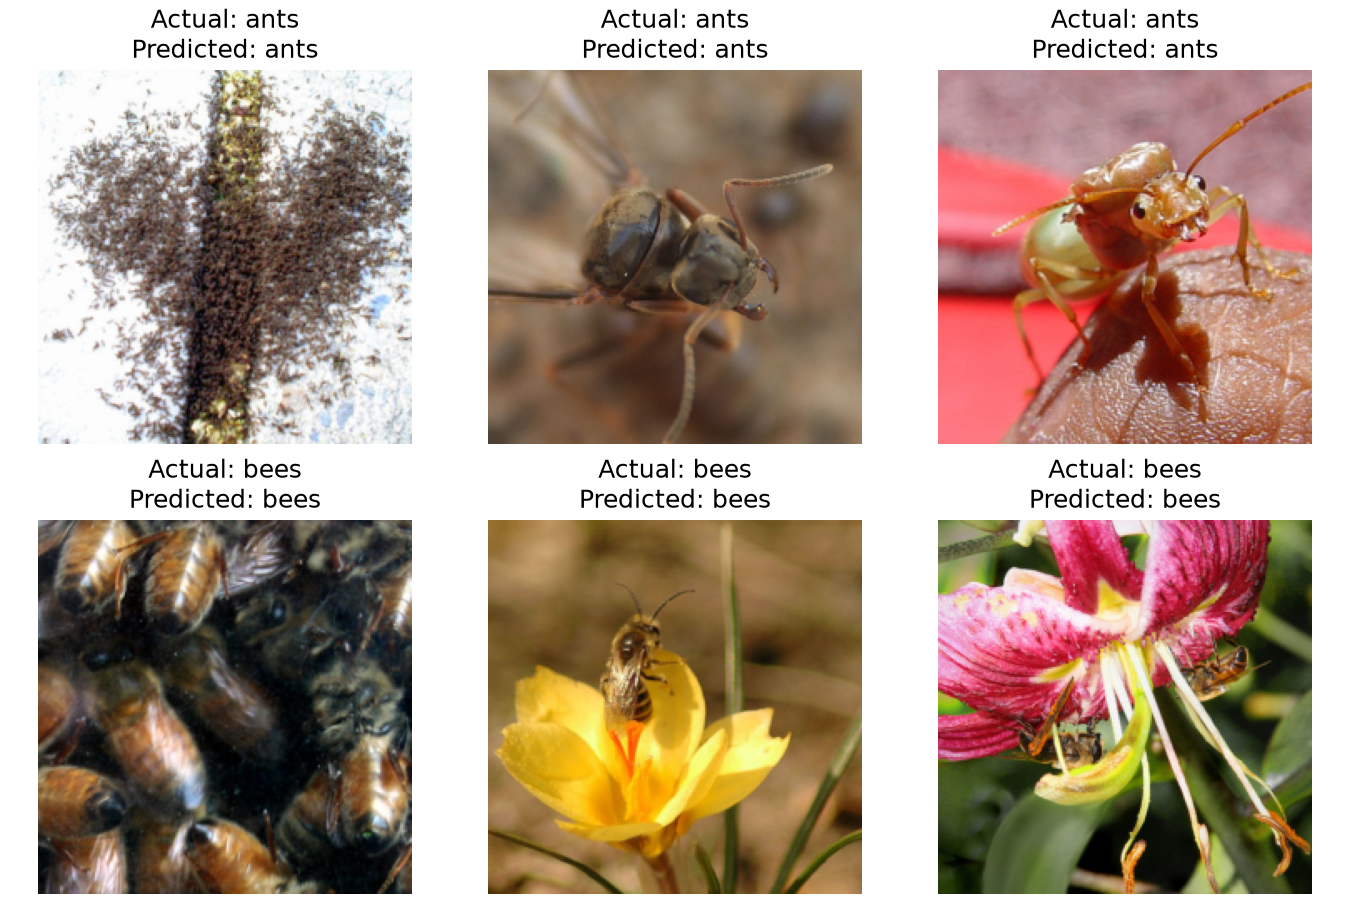

In [11]:
feature_model, feature_history, feature_epoch, feature_val = train_resnet(frozen=True)
print(f"Best validation accuracy: {feature_val['accuracy']:.2f}%")
print(f"Selected epoch: {feature_epoch} of {len(feature_history)}")
show_curves(feature_history, 'ResNet-18 feature extractor', second='val')
show_predictions(feature_model, transfer_loaders()['val'], next(feature_model.parameters()).device)


### Comparison of Results and Discussion

In [12]:
# Summary comparison tables across Q2 (MNIST) and Q3 (Hymenoptera Transfer Learning)
print("=== MNIST Classification Comparison (10 Epochs) ===")
print(f"{'Model':<15} {'Train Acc (%)':>14} {'Test Acc (%)':>14}")
print(f"{'LeNet-5':<15} {lenet_final['train_accuracy']:14.2f} {lenet_final['test_accuracy']:14.2f}")
print(f"{'Small CNN':<15} {cnn_final['train_accuracy']:14.2f} {cnn_final['test_accuracy']:14.2f}")
print()
print("=== Hymenoptera Transfer Learning Comparison (ResNet-18, 25 Epochs) ===")
print(f"{'Method':<20} {'Trainable Params':>17} {'Best Epoch':>12} {'Correct / 153':>15} {'Best Val Acc (%)':>18}")
print(f"{'Fine-tuning':<20} {11177538:17d} {fine_epoch:12d} {fine_val['correct']:15d} {fine_val['accuracy']:18.2f}")
print(f"{'Feature extractor':<20} {1026:17d} {feature_epoch:12d} {feature_val['correct']:15d} {feature_val['accuracy']:18.2f}")


=== MNIST Classification Comparison (10 Epochs) ===
Model           Train Acc (%)    Test Acc (%)
LeNet-5                 99.44           98.40
Small CNN               99.50           98.82

=== Hymenoptera Transfer Learning Comparison (ResNet-18, 25 Epochs) ===
Method               Trainable Params    Best Epoch    Correct / 153    Best Val Acc (%)
Fine-tuning                  11177538            17              143               93.46
Feature extractor                1026             1              146               95.42


#### Key Findings
1. **Dense Network vs. CNNs (Q1 & Q2):** A manually backpropagated two-layer dense network achieves $48.31\%$ test accuracy on CIFAR-10, whereas convolutional architectures exploit local spatial correlations and weight sharing to exceed $98\%$ on MNIST. Between the two MNIST models, the modern **Small CNN** ($98.82\%$) improves over **LeNet-5** ($98.40\%$) by $0.42$ percentage points ($42$ fewer errors) because BatchNorm2d, ReLU, MaxPool2d, and Dropout(0.25) stabilize gradient flow and prevent the late-epoch test loss rise seen in LeNet-5.
2. **Fine-Tuning vs. Feature Extraction (Q3):** On the small Hymenoptera dataset ($244$ training images), using ResNet-18 as a **frozen feature extractor** achieves **95.42% validation accuracy** ($146 / 153$ correct) while updating only $1,026$ linear classifier parameters—outperforming full **fine-tuning** ($93.46\%$, $143 / 153$ correct, $11.18\text{M}$ parameters) by **1.96 percentage points** ($3$ additional validation images). Because ants and bees are already well represented in ImageNet-1K features and the dataset is very small ($4$-image mini-batches), keeping the pretrained convolutional backbone and BatchNorm running statistics fixed avoids perturbing pretrained representations and converges rapidly in epoch 1, remaining stable at $95.42\%$ once StepLR decays the learning rate.